<a href="https://colab.research.google.com/github/ab110404/MAT422/blob/main/HW3.4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

HW 3.4

3.4. Logistic regression
- In this example, I will use logisitic regression to predict whether a student passes an exam based on hours studied.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(z):
  return 1 / (1 + np.exp(-z))

z = np.array([-2, -1, 0, 1, 2])
print("Sigmoid probabilities:")
print(np.round(sigmoid(z), 4))

Sigmoid probabilities:
[0.1192 0.2689 0.5    0.7311 0.8808]


- The sigmoid function has an S-shaped curve.
- When the input is negative, the probability approaches 0. When the input is positive, the probability approaches 1.
- When the input equals 0, the probability is 0.5.
- This makes the sigmoid function useful for binary classification problems.

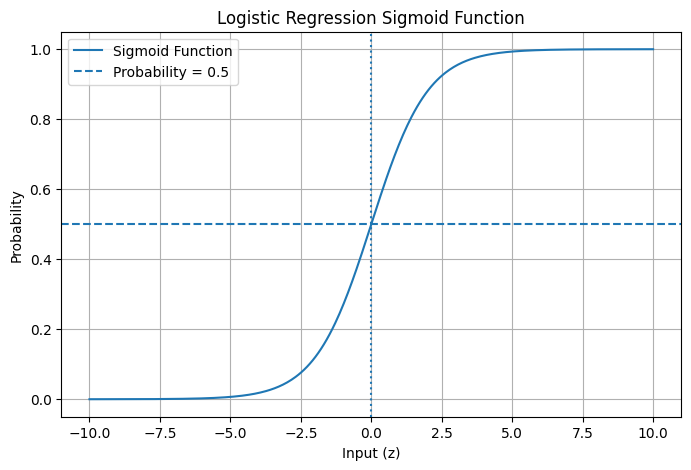

In [2]:
z_values = np.linspace(-10, 10, 400)
probabilities = sigmoid(z_values)
plt.figure(figsize=(8, 5))
plt.plot(z_values, probabilities, label="Sigmoid Function")
plt.axhline(0.5, linestyle="--", label="Probability = 0.5")
plt.axvline(0, linestyle=":")
plt.xlabel("Input (z)")
plt.ylabel("Probability")
plt.title("Logistic Regression Sigmoid Function")
plt.legend()
plt.grid(True)
plt.show()

- I will create a small dataset containing the number of hours students studied and whether they passed an exam.
- The outcome is represented by: 0=failed, 1=passed
- I will use logistic regression to model the relationship between study hours and the probability of passing.

In [3]:
hours = np.array([1, 2, 3, 4, 5, 6, 7, 8])
passed = np.array([0, 0, 0, 0, 1, 1, 1, 1])
print("Hours studied:", hours)
print("Exam results:", passed)

Hours studied: [1 2 3 4 5 6 7 8]
Exam results: [0 0 0 0 1 1 1 1]


- Gradient descent can be used to find the parameters of a logistic regression model.
- The model predicts probabilities using: p=1/(1 + exp(-(w*x + b)))
- The parameters w and b are updated repeatedly to reduce the binary cross-entropy loss.
- I will use gradient descent to train the model on the student exam dataset.

In [4]:
w = 0.0
b = 0.0
alpha = 0.1
iterations = 5000

n = len(hours)
for i in range(iterations):
  z = w * hours + b
  predictions = sigmoid(z)
  dw = np.mean((predictions - passed) * hours)
  db = np.mean(predictions - passed)
  w = w - alpha * dw
  b = b - alpha * db
print("Weight:", round(w, 4))
print("Bias:", round(b, 4))

Weight: 2.4629
Bias: -10.9179


- After training the model, I can use the learned parameters to predict the probability that a student passes an exam.
- A probability of 0.5 or greater will be classified as passing, while a probability below 0.5 will be classified as failing.

In [5]:
test_hours = np.array([2, 4, 5, 7])
test_probabilities = sigmoid(w * test_hours + b)
test_predictions = (test_probabilities >= 0.5).astype(int)
for h, p, result in zip(
    test_hours, test_probabilities, test_predictions
):
    print(
        f"Hours: {h}, Probability: {p:.4f}, "
        f"Prediction: {result}"
    )

Hours: 2, Probability: 0.0025, Prediction: 0
Hours: 4, Probability: 0.2561, Prediction: 0
Hours: 5, Probability: 0.8016, Prediction: 1
Hours: 7, Probability: 0.9982, Prediction: 1


- I will graph the original exam results and the predicted probability curve.
- The graph will show how the probability of passing increases as the number of hours studied increases.
- The logistic regression curve provides a smooth transition between the two classification outcomes.

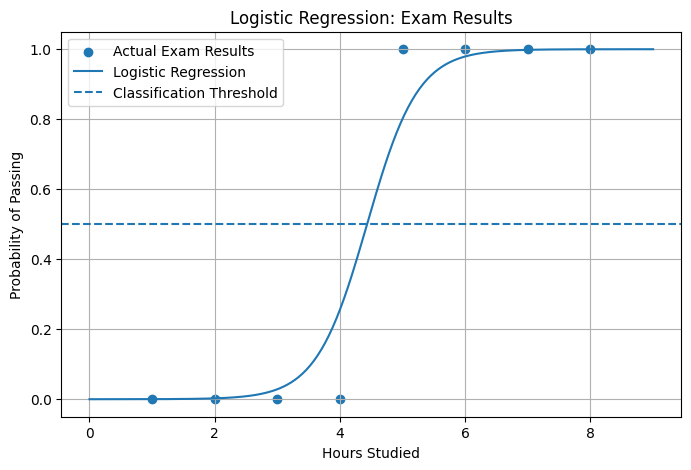

In [6]:
x_values = np.linspace(0, 9, 300)
y_probabilities = sigmoid(w * x_values + b)

plt.figure(figsize=(8, 5))
plt.scatter(
    hours, passed,
    label="Actual Exam Results"
)

plt.plot(
    x_values, y_probabilities,
    label="Logistic Regression"
)

plt.axhline(
    0.5, linestyle="--",
    label="Classification Threshold"
)

plt.xlabel("Hours Studied")
plt.ylabel("Probability of Passing")
plt.title("Logistic Regression: Exam Results")
plt.legend()
plt.grid(True)
plt.show()

Conclusion:
- In this section, I explored logisitic regression as a method for binary classification.
- I used the sigmoid function to convert numerical values into probabilities between 0 and 1.
- I also created a dataset containing study hours and exam results, then used gradient descent to train a logistic regression model.
- The model predicted that students who studied more hours had a higher probability of passing the exam.
- Overall, this example demonstrates how logistic regression and gradient descent work together to solve binary classification problems.